In [ ]:
%load_ext autoreload
%autoreload 2
import os
from pathlib import Path
import numpy as np
import polars as pl
import pandas as pd
from utils import coevolution_forest, pipeline_v2, funcs
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.metrics import (f1_score, classification_report,ConfusionMatrixDisplay, roc_curve, auc)
from sklearn.preprocessing import label_binarize
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [45]:
train=pl.read_parquet(r'data\data-RF\train_glove_tfidf.parquet')
val=pl.read_parquet(r'data\data-RF\val_glove_tfidf.parquet')

In [46]:
splits = pl.read_parquet("data/splits.parquet")
val_ids = splits.filter(pl.col("split") == "val")["id"]

In [47]:
X_train=train.drop(['genre'])
y_train=train['genre']
X_val=val.drop(['genre'])
y_val=val['genre']

In [48]:
rfc = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=0,
)
rfc.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
hgb = HistGradientBoostingClassifier(
    max_iter=300, min_samples_leaf=5, early_stopping=True,
    n_iter_no_change=10, validation_fraction=0.1, random_state=0
)
hgb.fit(X_train.toarray(), y_train)

In [ ]:
gbc = GradientBoostingClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    random_state=0
)
gbc.fit(X_train,y_train)

In [ ]:
print('RandomForest')
print('---------------------')
print(f'training: {rfc.score(X_train, y_train)}, testing: {rfc.score(X_val, y_val)}')
print('======================')
print('GradientBoosting')
print('---------------------')
print(f'training: {gbc.score(X_train, y_train)}, testing: {gbc.score(X_val, y_val)}')
print('======================')
print('HistGradientBoosting')
print('---------------------')
print(f'training: {hgb.score(X_train, y_train)}, testing: {hgb.score(X_val, y_val)}')

0.6336613123110664

train accuracy: 0.909
val accuracy:   0.634  (always guessing the biggest genre: 0.413)
macro F1:       0.461
weighted F1:    0.618
              precision    recall  f1-score   support

     country       0.37      0.05      0.08       866
        misc       0.54      0.59      0.57      1410
         pop       0.62      0.70      0.65     13936
         rap       0.80      0.85      0.82      9646
          rb       0.28      0.20      0.23      1551
        rock       0.46      0.36      0.41      6333

    accuracy                           0.63     33742
   macro avg       0.51      0.46      0.46     33742
weighted avg       0.61      0.63      0.62     33742



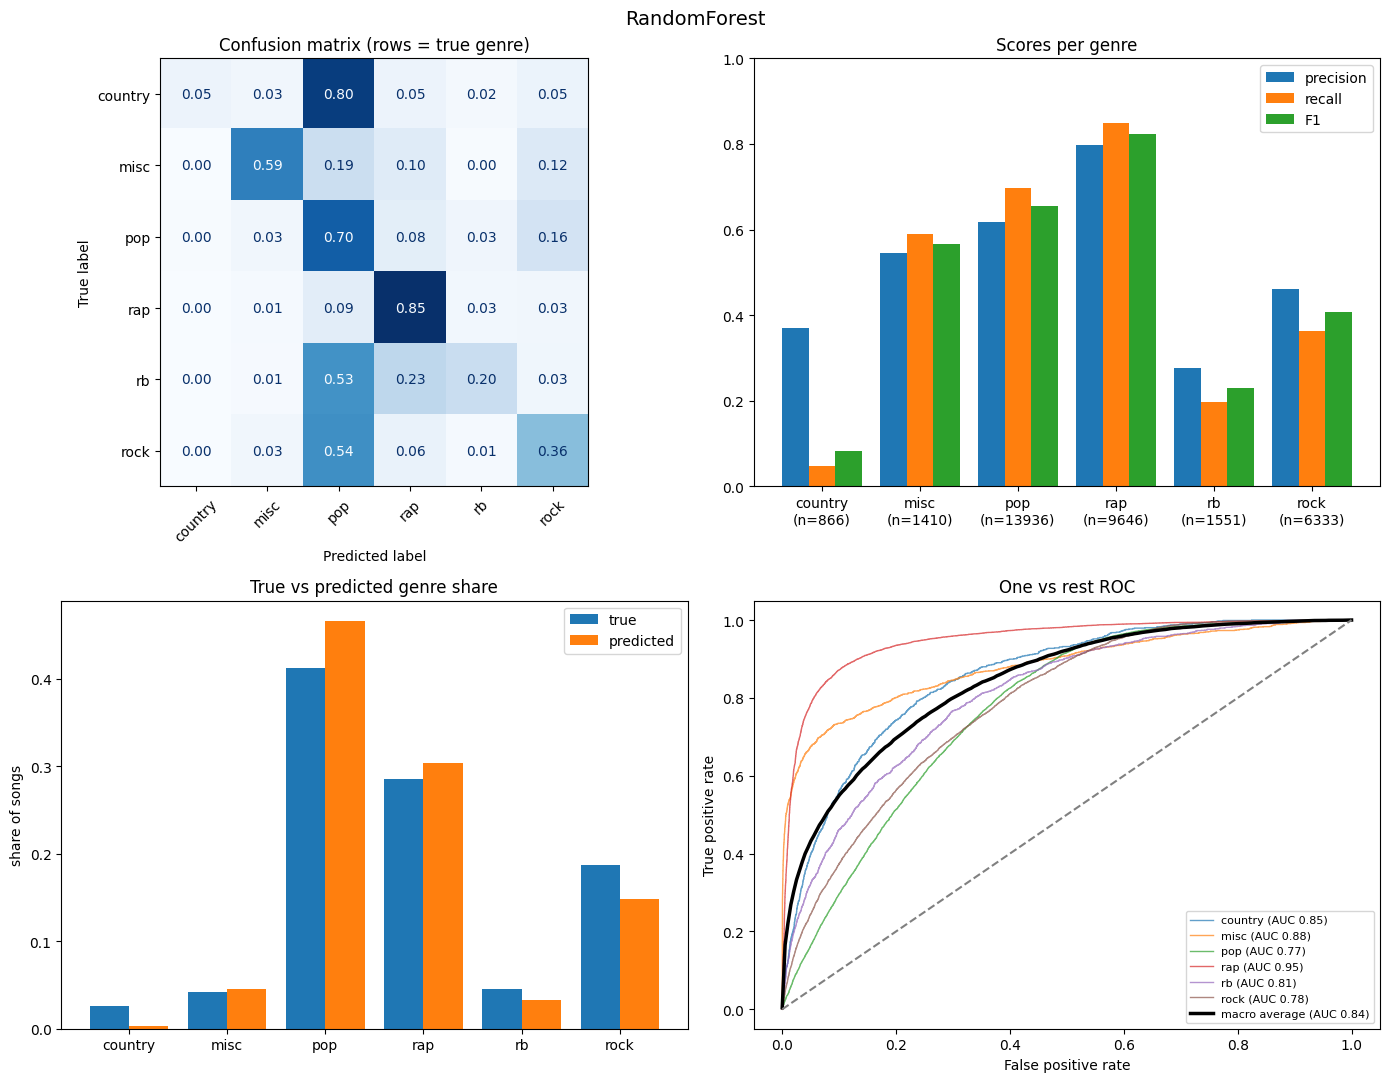

val accuracy:   0.369  (always guessing the biggest genre: 0.413)
macro F1:       0.305
weighted F1:    0.357
              precision    recall  f1-score   support

     country       0.06      0.41      0.11       866
        misc       0.21      0.71      0.32      1410
         pop       0.62      0.07      0.13     13936
         rap       0.77      0.78      0.78      9646
          rb       0.12      0.51      0.20      1551
        rock       0.34      0.27      0.30      6333

    accuracy                           0.37     33742
   macro avg       0.35      0.46      0.31     33742
weighted avg       0.56      0.37      0.36     33742



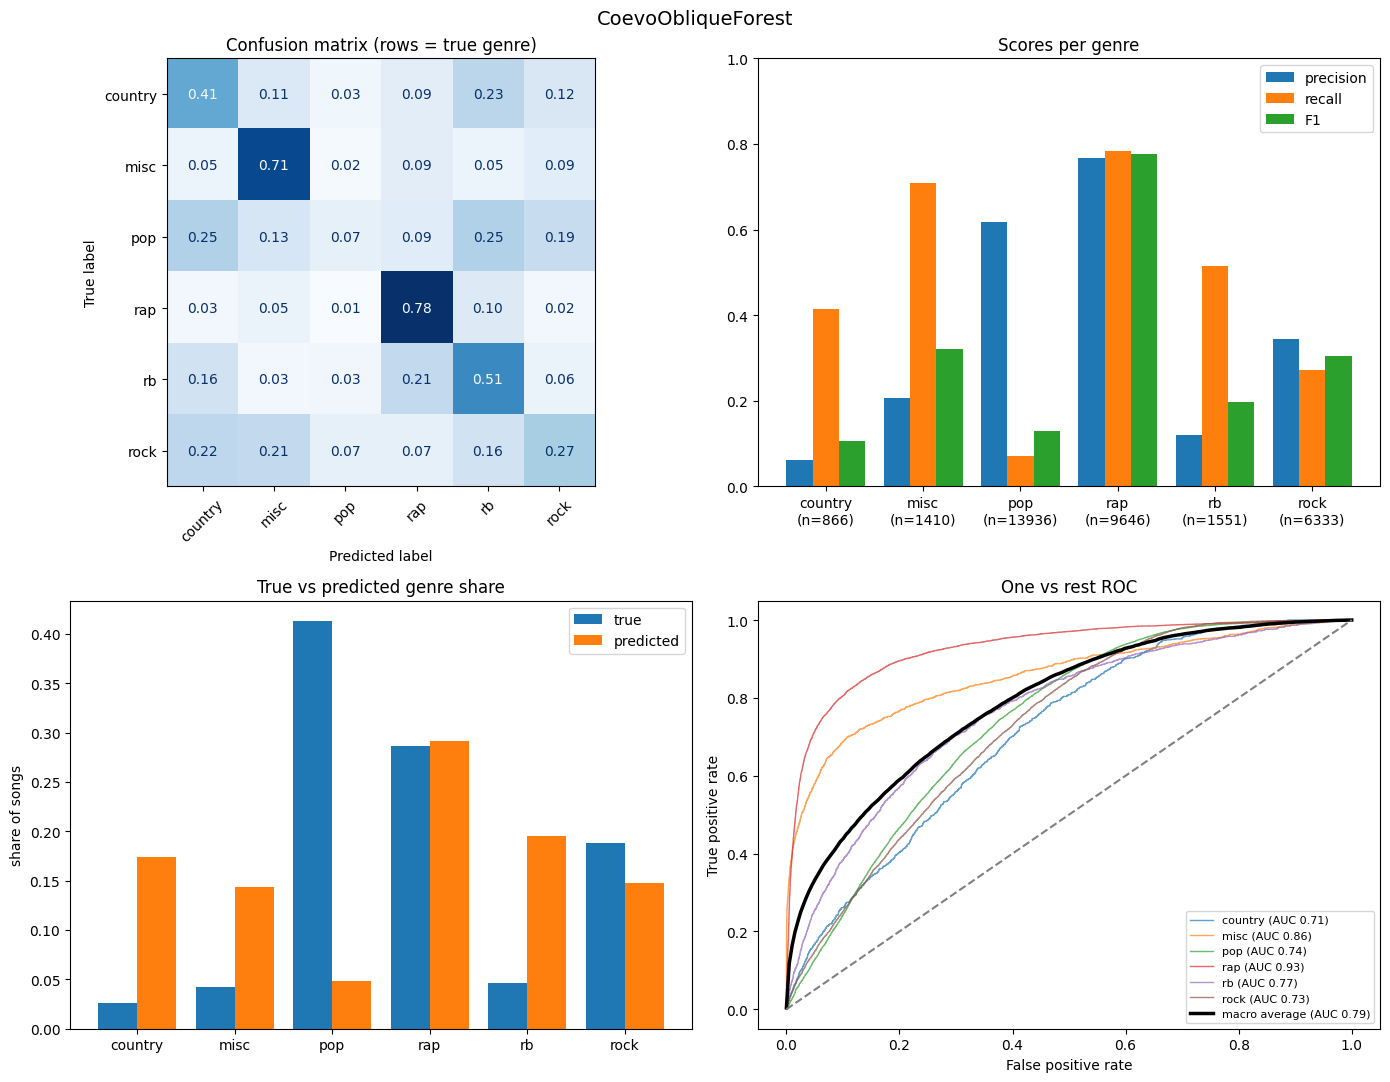

{'accuracy': 0.36870962005808783,
 'macro_f1': 0.30526629896842855,
 'weighted_f1': 0.3571956824511337}

In [ ]:
from utils.funcs import diagnose

# sklearn random forest
diagnose(y_val, rfc.predict_proba(X_val), rfc.classes_,
         name="RandomForest", train_accuracy=rfc.score(X_train, y_train))

# sklearn gradient boosting
diagnose(y_val, gbc.predict_proba(X_val), gbc.classes_,
         name="GradientBoosting", train_accuracy=gbc.score(X_train, y_train))

# sklearn gradient boosting
diagnose(y_val, hgb.predict_proba(X_val), hgb.classes_,
         name="HistGradientBoosting", train_accuracy=hgb.score(X_train, y_train))


In [ ]:
test_df = pl.read_parquet('data/data-RF/test_glove_tfidf.parquet')

In [ ]:
df_submission = test_df.select("id").with_columns(
    pl.Series(name="tag", values=rfc.predict(test_df))
)

In [ ]:
df_submission.write_csv('group5_2nd_submit.csv')